# Phase 1 — EMNIST: load, orientation fix, augmentation (sanity checks)

**Gate ("Done when")**: train/val/test pipelines with *visually confirmed* orientation,
values in [0,1], augmentation on train only, `label_map.json` + `labels.txt` saved.

Run every cell top-to-bottom. The visual checks are the point of this notebook — look at them carefully.

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))  # so `src` is importable from notebooks/

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import string

print("TF:", tf.__version__)

TF: 2.19.1


## 1. Load raw EMNIST/letters
First run downloads ~536 MB to `~/tensorflow_datasets`.

In [2]:
(ds_train_raw, ds_test_raw), info = tfds.load(
    'emnist/letters', split=['train', 'test'],
    as_supervised=True, with_info=True)

print(info.splits)
print("classes:", info.features['label'].num_classes)  # 37 in metadata, but letters uses 1..26

{'train': <SplitInfo num_examples=88800, num_shards=1>, 'test': <SplitInfo num_examples=14800, num_shards=1>}
classes: 37


## 2. Orientation check — BEFORE the fix
Raw EMNIST is **transposed/flipped**. The letters below should look wrong (mirrored/sideways).
The title shows the ground-truth letter (label 1=a ... 26=z).

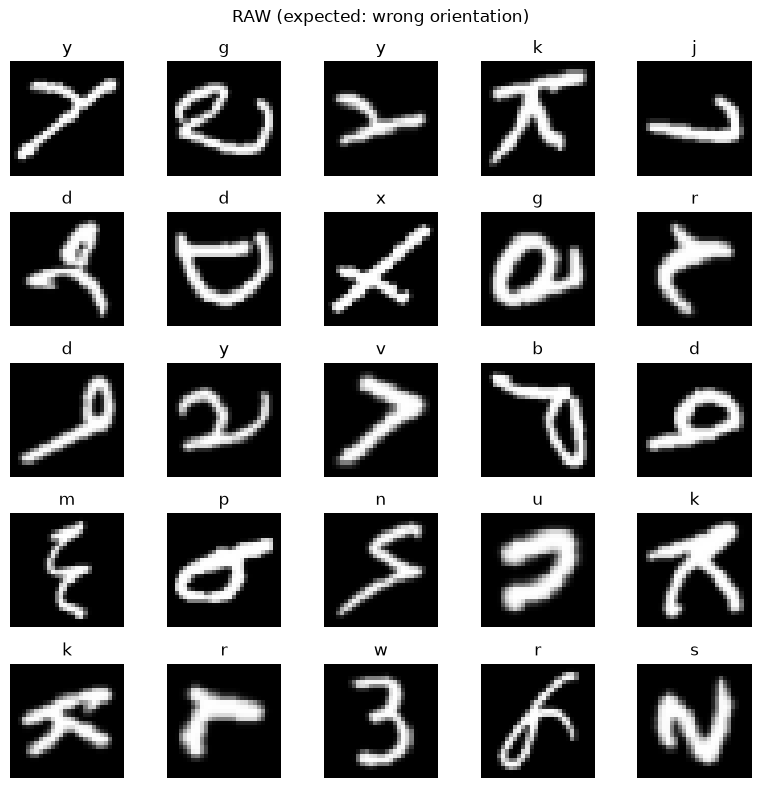

In [3]:
def show_grid(ds, transform=None, n=25, title=''):
    fig, axes = plt.subplots(5, 5, figsize=(8, 8))
    for ax, (img, lab) in zip(axes.flat, ds.take(n)):
        x = transform(img) if transform else img
        ax.imshow(tf.squeeze(x), cmap='gray')
        ax.set_title(string.ascii_lowercase[int(lab) - 1])
        ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_grid(ds_train_raw, transform=None, title='RAW (expected: wrong orientation)')

## 3. Orientation check — AFTER the fix
Now every letter must read **normally**: not mirrored, not sideways, and it must match the title.
If anything looks off, adjust `fix_orientation` in `src/data.py` and re-run — do NOT proceed.

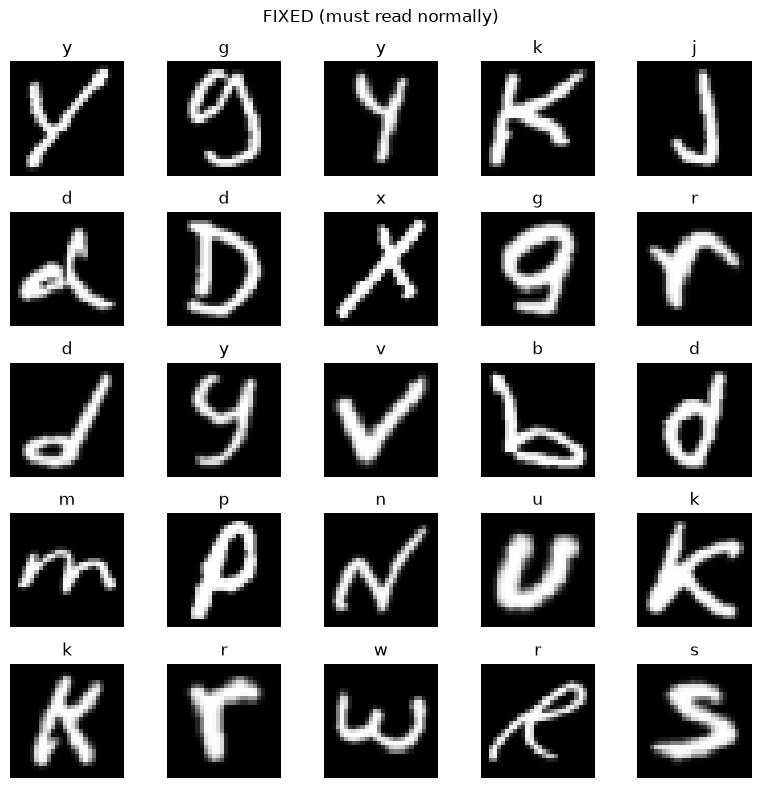

In [4]:
from src.data import fix_orientation
show_grid(ds_train_raw, transform=fix_orientation, title='FIXED (must read normally)')

## 4. Normalization + relabel checks

In [5]:
from src.data import get_datasets, dataset_stats, NUM_CLASSES

ds_train, ds_val, ds_test, info = get_datasets()

xb, yb = next(iter(ds_train))
print("batch:", xb.shape, xb.dtype)
print("value range: [%.3f, %.3f]  (must be within [0,1])" % (xb.numpy().min(), xb.numpy().max()))
print("label range: %d..%d  (must be 0..25)" % (int(yb.numpy().min()), int(yb.numpy().max())))
assert 0.0 <= xb.numpy().min() and xb.numpy().max() <= 1.0
assert 0 <= int(yb.numpy().min()) and int(yb.numpy().max()) <= NUM_CLASSES - 1
print("OK")

batch: (128, 28, 28, 1) <dtype: 'float32'>
value range: [0.000, 1.000]  (must be within [0,1])
label range: 0..25  (must be 0..25)
OK


## 5. Augmentation check (train only)
Left: the same character class from the *validation* pipeline (clean, deterministic).
Right: augmented training samples — rotated/shifted/zoomed, thickness-varied, noisy.
Val/test must stay clean; train should look visibly perturbed but still legible.

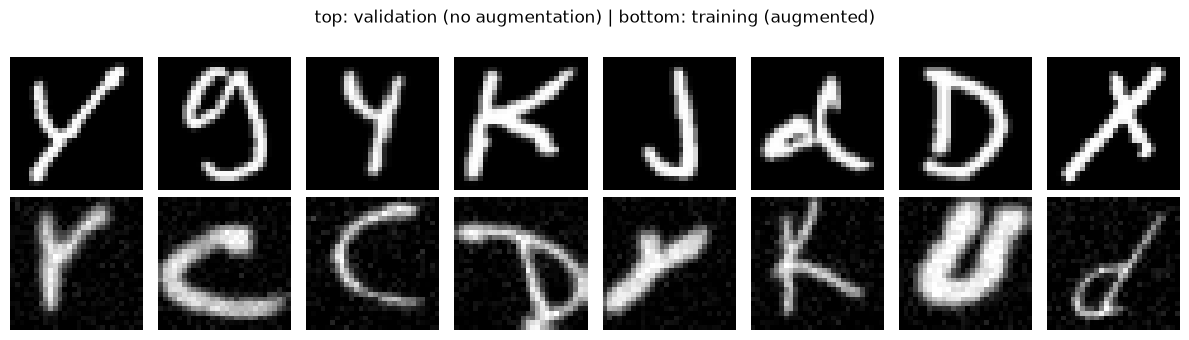

In [6]:
xv, yv = next(iter(ds_val))
xt, yt = next(iter(ds_train))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(tf.squeeze(xv[i]), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(tf.squeeze(xt[i]), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('val (clean)')
axes[1, 0].set_ylabel('train (aug)')
fig.suptitle('top: validation (no augmentation) | bottom: training (augmented)')
plt.tight_layout(); plt.show()

## 6. Class balance (report material)

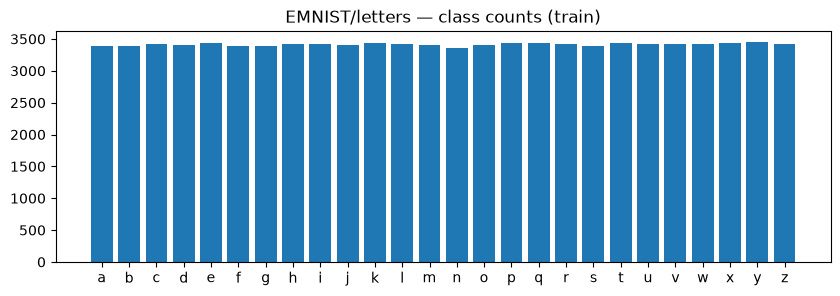

min/max per class: 3365 3453


In [7]:
import collections
counts = collections.Counter()
for _, lab in tfds.load('emnist/letters', split='train', as_supervised=True):
    counts[int(lab)] += 1

letters = [string.ascii_lowercase[k-1] for k in sorted(counts)]
vals = [counts[k] for k in sorted(counts)]
plt.figure(figsize=(10, 3))
plt.bar(letters, vals)
plt.title('EMNIST/letters — class counts (train)'); plt.show()
print('min/max per class:', min(vals), max(vals))

## 7. Save label artifacts + dataset stats

In [8]:
import json
from src.data import write_label_artifacts, dataset_stats, ARTIFACTS

write_label_artifacts()
stats = dataset_stats(info)
json.dump(stats, open(ARTIFACTS / 'dataset_stats.json', 'w'), indent=2)
print(json.dumps(stats, indent=2))
print('\nSaved:', sorted(p.name for p in ARTIFACTS.iterdir()))

{
  "dataset": "emnist/letters (tfds train split only; tfds test is broken)",
  "num_classes": 26,
  "source_total": 88800,
  "train_fit": 71040,
  "val": 8880,
  "test": 8880,
  "image_shape": [
    28,
    28,
    1
  ],
  "label_range_raw": "1..26 (relabeled to 0..25)",
  "note": "tfds 'test' split excluded: contains only classes a-s (t-z absent); val/test carved 10%/10% from tfds 'train'."
}

Saved: ['baseline.keras', 'chosen_model.json', 'confusion_matrix.png', 'dataset_stats.json', 'efficiency_study.json', 'label_map.json', 'labels.txt', 'model.keras', 'separable.keras']


## 7. Dataset Validation

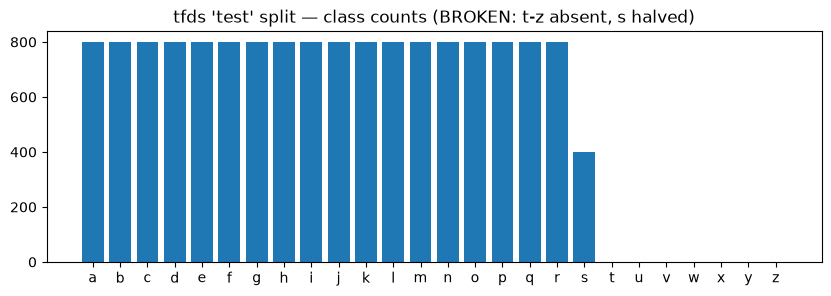

total: 14800 | per class: {'a': np.int64(800), 'b': np.int64(800), 'c': np.int64(800), 'd': np.int64(800), 'e': np.int64(800), 'f': np.int64(800), 'g': np.int64(800), 'h': np.int64(800), 'i': np.int64(800), 'j': np.int64(800), 'k': np.int64(800), 'l': np.int64(800), 'm': np.int64(800), 'n': np.int64(800), 'o': np.int64(800), 'p': np.int64(800), 'q': np.int64(800), 'r': np.int64(800), 's': np.int64(400), 't': np.int64(0), 'u': np.int64(0), 'v': np.int64(0), 'w': np.int64(0), 'x': np.int64(0), 'y': np.int64(0), 'z': np.int64(0)}


In [9]:
# Evidence: tfds emnist/letters 'test' split is truncated (classes t-z absent)
import tensorflow_datasets as tfds, numpy as np, string
import matplotlib.pyplot as plt

ds_broken = tfds.load('emnist/letters', split='test', as_supervised=True)
ys = np.array([int(y) for _, y in ds_broken]) - 1
counts = np.bincount(ys, minlength=26)

plt.figure(figsize=(10, 3))
plt.bar(list(string.ascii_lowercase), counts)
plt.title("tfds 'test' split — class counts (BROKEN: t-z absent, s halved)")
plt.savefig('../artifacts/broken_tfds_test_split.png', dpi=150, bbox_inches='tight')
plt.show()
print('total:', counts.sum(), '| per class:', dict(zip(string.ascii_lowercase, counts)))

## Gate checklist (Phase 1 "Done when")
- [X] Section 3: letters read normally after the fix (verified **visually, twice** — re-run the cell)
- [X] Section 4: values in [0,1], labels 0..25
- [X] Section 5: augmentation visible on train, val clean
- [X] Section 7: `label_map.json`, `labels.txt`, `dataset_stats.json` in `ml/artifacts/`
- [X] `git commit` — phase checkpoint